# Practical 3: Bank Customer Churn (Neural Network)

**Aim:** Build a neural-network classifier that predicts whether a bank customer will leave in the next 6 months. Print the accuracy score and confusion matrix, and implement improvements.

**Steps:** read data, split features and target, normalise, build a base model, identify improvements (Dropout, Early Stopping, class weights), implement them, evaluate.

## Setup: libraries and dataset loader

The loader tries Kaggle first. If the download fails, it asks you to upload the CSV (a file picker appears). You can also drag the CSV into the Colab Files panel before running.

In [1]:
!pip install -q kagglehub

import os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

def get_dataset(kaggle_handle, filename, fallback_url=None, fallback_kwargs=None, **read_kwargs):
    """Load a CSV. Order: (1) file already in the Colab workspace, (2) Kaggle via kagglehub,
    (3) optional public fallback URL, (4) manual upload prompt."""
    # 1. already present (e.g. you dragged it into the Colab Files panel)
    for p in [filename, f"/content/{filename}"]:
        if os.path.exists(p):
            print("Using existing file:", p)
            return pd.read_csv(p, **read_kwargs)
    # 2. Kaggle
    try:
        import kagglehub
        folder = kagglehub.dataset_download(kaggle_handle)
        hits = glob.glob(os.path.join(folder, "**", filename), recursive=True)
        if hits:
            print("Downloaded from Kaggle:", hits[0])
            return pd.read_csv(hits[0], **read_kwargs)
        print("Kaggle download worked but", filename, "was not found inside it.")
    except Exception as e:
        print("Kaggle download failed:", type(e).__name__, str(e)[:200])
    # 3. public fallback
    if fallback_url:
        try:
            print("Trying fallback URL ...")
            return pd.read_csv(fallback_url, **(fallback_kwargs or read_kwargs))
        except Exception as e:
            print("Fallback failed:", type(e).__name__)
    # 4. manual upload
    print(f"Please upload {filename} (download it from https://www.kaggle.com/datasets/{kaggle_handle})")
    from google.colab import files
    up = files.upload()
    name = next(iter(up))
    return pd.read_csv(name, **read_kwargs)

print("Setup complete")

Setup complete


In [2]:
from sklearn.model_selection import train_test_split

In [3]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
tf.random.set_seed(42); np.random.seed(42)

# 1. Read dataset
df3 = get_dataset("barelydedicated/bank-customer-churn-modeling", "Churn_Modelling.csv")
print(df3.shape)
print(df3["Exited"].value_counts())
df3.head()

100%|██████████| 262k/262k [00:00<00:00, 22.5MB/s]

Extracting files...
Downloaded from Kaggle: /root/.cache/kagglehub/datasets/barelydedicated/bank-customer-churn-modeling/versions/1/Churn_Modelling.csv
(10000, 14)
Exited
0    7963
1    2037
Name: count, dtype: int64


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [4]:
# 2. Feature and target sets, train/test split
df3 = df3.drop(columns=["RowNumber", "CustomerId", "Surname"])
df3 = pd.get_dummies(df3, columns=["Geography", "Gender"], drop_first=True)
X3 = df3.drop(columns=["Exited"]).astype("float32")
y3 = df3["Exited"]
X3_train, X3_test, y3_train, y3_test = train_test_split(X3, y3, test_size=0.2, random_state=42, stratify=y3)

# 3. Normalise (fit on train only)
sc = StandardScaler()
X3_train = sc.fit_transform(X3_train)
X3_test = sc.transform(X3_test)
print(X3_train.shape, X3_test.shape)

(8000, 11) (2000, 11)


### 3.4a Base model

In [5]:
base = Sequential([Input(shape=(X3_train.shape[1],)),
                   Dense(6, activation="relu"), Dense(6, activation="relu"),
                   Dense(1, activation="sigmoid")])
base.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
base.fit(X3_train, y3_train, epochs=50, batch_size=32, validation_split=0.2, verbose=0)
base_pred = (base.predict(X3_test, verbose=0) > 0.5).astype(int).ravel()
print("Base model accuracy:", round(accuracy_score(y3_test, base_pred), 4))
print("Base confusion matrix:\n", confusion_matrix(y3_test, base_pred))

Base model accuracy: 0.8565
Base confusion matrix:
 [[1525   68]
 [ 219  188]]


### 3.4b Points of improvement and improved model
1. **Overfitting** is reduced with *Dropout* and *Early Stopping*.
2. **Class imbalance** (only about 20% of customers leave) is handled with *class weights*.
3. A **wider network** (32 and 16 neurons) can learn more patterns.

In [6]:
neg, pos = np.bincount(y3_train)
class_weight = {0: 1.0, 1: neg / pos}

model = Sequential([Input(shape=(X3_train.shape[1],)),
                    Dense(32, activation="relu"), Dropout(0.3),
                    Dense(16, activation="relu"), Dropout(0.2),
                    Dense(1, activation="sigmoid")])
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
early = EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
history = model.fit(X3_train, y3_train, epochs=150, batch_size=32, validation_split=0.2,
                    callbacks=[early], class_weight=class_weight, verbose=0)
print("Stopped after", len(history.history["loss"]), "epochs")

Stopped after 79 epochs


### 3.5 Accuracy score and confusion matrix

Improved model accuracy: 0.776
Confusion Matrix:
 [[1229  364]
 [  84  323]]
              precision    recall  f1-score   support

       Stays       0.94      0.77      0.85      1593
      Leaves       0.47      0.79      0.59       407

    accuracy                           0.78      2000
   macro avg       0.70      0.78      0.72      2000
weighted avg       0.84      0.78      0.79      2000



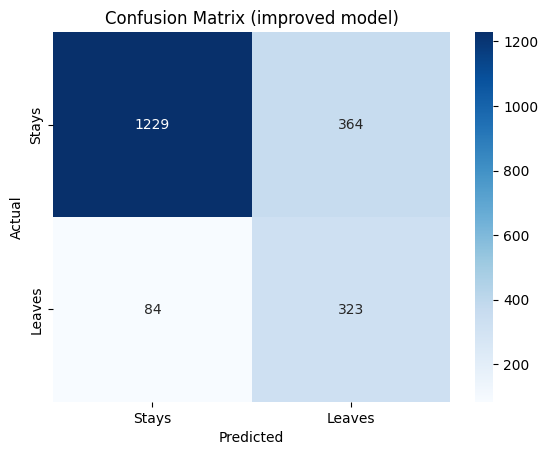

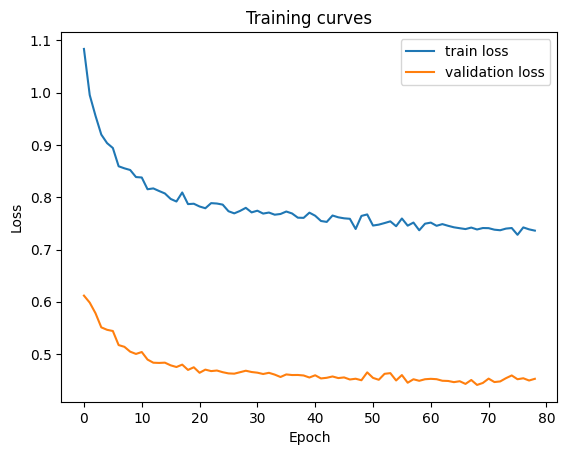

In [7]:
y3_pred = (model.predict(X3_test, verbose=0) > 0.5).astype(int).ravel()
print("Improved model accuracy:", round(accuracy_score(y3_test, y3_pred), 4))
cm3 = confusion_matrix(y3_test, y3_pred)
print("Confusion Matrix:\n", cm3)
print(classification_report(y3_test, y3_pred, target_names=["Stays", "Leaves"]))

sns.heatmap(cm3, annot=True, fmt="d", cmap="Blues", xticklabels=["Stays", "Leaves"], yticklabels=["Stays", "Leaves"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion Matrix (improved model)"); plt.show()

plt.plot(history.history["loss"], label="train loss"); plt.plot(history.history["val_loss"], label="validation loss")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend(); plt.title("Training curves"); plt.show()

**Conclusion (Practical 3):** The improved model trades a little overall accuracy for much better recall on customers who leave, which is the more useful result for a bank.